In [1]:
import pandas as pd
import numpy as np



In [5]:
# Load dataset (using latin-1 encoding for special characters)
df = pd.read_csv('spam.csv', encoding='latin-1')

# Keep only the relevant columns and rename them
df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})

# Check class distribution counts and percentages
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True) * 100)

label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [11]:
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# 1. Download required NLTK resources
nltk.download('stopwords')
nltk.download('wordnet')

# 2. Load dataset and correctly rename columns
df = pd.read_csv('spam.csv', encoding='latin-1')
df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})

# 3. Initialize preprocessors
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = str(text).lower()
    # Remove punctuation
    text = "".join([char for char in text if char not in string.punctuation])
    # Tokenize, remove stopwords, and lemmatize
    words = text.split()
    cleaned_words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]
    return " ".join(cleaned_words)

# 4. Apply preprocessing safely
df['cleaned_text'] = df['text'].apply(preprocess_text)

# Verify it works
print("Preprocessing complete! Preview:")
print(df[['text', 'cleaned_text']].head())

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/f8450f7e-39c0-48a4-b9a7-
[nltk_data]     9e8e1060928e/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/f8450f7e-39c0-48a4-b9a7-
[nltk_data]     9e8e1060928e/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Preprocessing complete! Preview:
                                                text  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                        cleaned_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry 2 wkly comp win fa cup final tkts 2...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Feature Extraction using TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=3000)
X = tfidf.fit_transform(df['cleaned_text']).toarray()

# Encode labels: ham = 0, spam = 1
y = df['label'].map({'ham': 0, 'spam': 1})

# 2. Train/Test Split (Stratified to maintain class proportions)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Train Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

# 4. Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# 5. Evaluate Performance
print("--- Multinomial Naive Bayes Performance ---")
print("Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(y_test, nb_pred))

print("\n--- Logistic Regression Performance ---")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

--- Multinomial Naive Bayes Performance ---
Accuracy: 0.9713004484304932
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       966
           1       0.99      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115


--- Logistic Regression Performance ---
Accuracy: 0.9623318385650225
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       966
           1       0.98      0.73      0.84       149

    accuracy                           0.96      1115
   macro avg       0.97      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



In [14]:
!pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 1.9 MB/s  0:00:00m4.4 MB/s eta 0:00:01
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Looking in links: /usr/share/pip-wheels


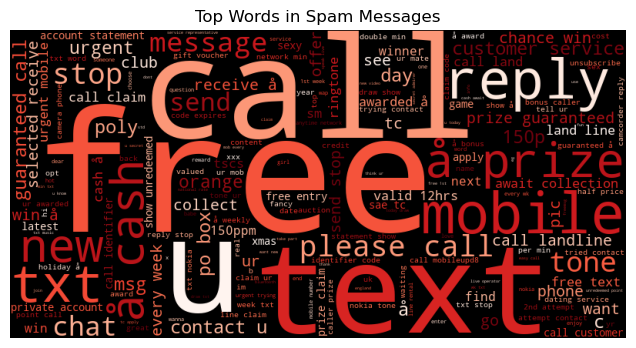

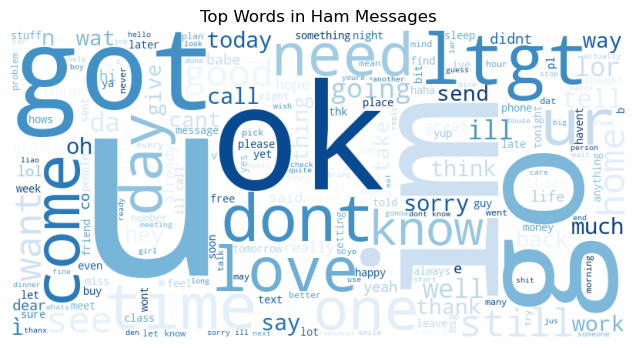

In [19]:
import sys
import subprocess

# Force-install and add user site-packages to path so the current kernel sees it instantly
subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "wordcloud"])
import site
import importlib
importlib.reload(site)

# Now import and run
import matplotlib.pyplot as plt
from wordcloud import WordCloud

spam_text = " ".join(df[df['label'] == 'spam']['cleaned_text'])
ham_text = " ".join(df[df['label'] == 'ham']['cleaned_text'])

# Generate Spam WordCloud
plt.figure(figsize=(8, 4))
plt.imshow(WordCloud(width=800, height=400, background_color='black', colormap='Reds').generate(spam_text))
plt.title("Top Words in Spam Messages")
plt.axis('off')
plt.show()

# Generate Ham WordCloud
plt.figure(figsize=(8, 4))
plt.imshow(WordCloud(width=800, height=400, background_color='white', colormap='Blues').generate(ham_text))
plt.title("Top Words in Ham Messages")
plt.axis('off')
plt.show()

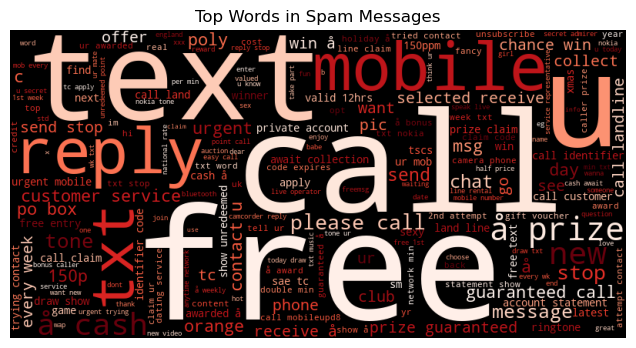

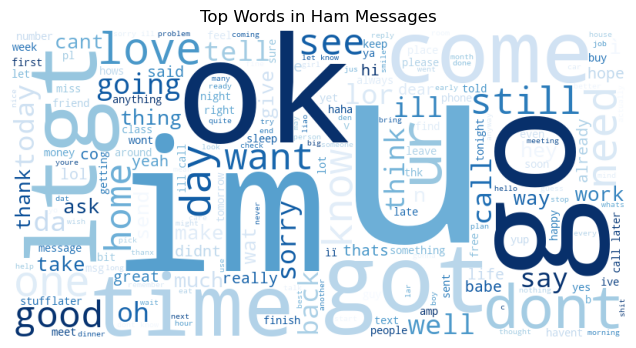

In [20]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Separate spam and ham text
spam_text = " ".join(df[df['label'] == 'spam']['cleaned_text'])
ham_text = " ".join(df[df['label'] == 'ham']['cleaned_text'])

# Generate Spam WordCloud
plt.figure(figsize=(8, 4))
plt.imshow(WordCloud(width=800, height=400, background_color='black', colormap='Reds').generate(spam_text))
plt.title("Top Words in Spam Messages")
plt.axis('off')
plt.show()

# Generate Ham WordCloud
plt.figure(figsize=(8, 4))
plt.imshow(WordCloud(width=800, height=400, background_color='white', colormap='Blues').generate(ham_text))
plt.title("Top Words in Ham Messages")
plt.axis('off')
plt.show()